# DINOv3-B + DPT on LuSNAR: semantic segmentation, then depth (two separate models)

Both tasks use **the same architecture** and differ only in the head:

```
image ─► DINOv3 ViT-B/16 ─► tokens of blocks [2, 5, 8, 11]  (4 × [B, 768, H/16, W/16])
                         ─► DPT neck: reassemble to 1/4, 1/8, 1/16, 1/32 → fusion → [B, 256, H/2, W/2]
                         ├─► SegHead   : conv-BN-ReLU → 1×1 → 5 logits        → upsample to H×W
                         └─► DepthHead : conv-ReLU → 1×1 → N log-spaced bins → softmax-weighted log-depth → upsample
```

The two models are trained **one after the other, each with its own backbone copy** (no weight sharing yet):

1. Section 4: segmentation (weighted cross-entropy + Dice) → mIoU
2. Section 5: depth (SILog + gradient-matching loss) → AbsRel, RMSE, δ<1.25

Default: frozen backbone (only neck and head train). Set `UNFREEZE_LAST_N > 0` to fine-tune the last blocks with `BACKBONE_LR`.

Needs `lusnar_dataset.py` next to this notebook, plus `torch numpy pandas pillow matplotlib transformers`.
The backbone `facebook/dinov3-vitb16-pretrain-lvd1689m` is **gated** on Hugging Face: accept the licence and
`huggingface-cli login` first (on the cluster, download on a login node). Without access the notebook falls
back to random weights, which only tests the plumbing.

## 0. Configuration

In [21]:
from pathlib import Path

ROOT = Path("/proj/uppmax2026-1-299/task1_groupc_dataset/lusnar/extracted")   # folder with Moon_1 … Moon_9
def _find_code_dir(name="lusnar_dataset.py"):
    """Folder containing lusnar_dataset.py: the notebook's folder (VS Code), else cwd or one of its parents."""
    cands = [Path(globals()["__vsc_ipynb_file__"]).parent] if "__vsc_ipynb_file__" in globals() else []
    cands += [Path.cwd(), *Path.cwd().parents]
    for d in cands:
        if (d / name).exists():
            return d
    raise FileNotFoundError(f"{name} not found in {[str(c) for c in cands[:3]]} ... - set CODE_DIR by hand")

UPPMAX_CODE_DIR = Path("/proj/uppmax2026-1-299/task1_groupc_dataset")   # copy of lusnar_dataset.py on UPPMAX
CODE_DIR = UPPMAX_CODE_DIR if (UPPMAX_CODE_DIR / "lusnar_dataset.py").exists() else _find_code_dir()
print("CODE_DIR:", CODE_DIR)

# --- data ---
IMAGE_SIZE = 512                    # multiple of 16 (DINOv3 patch size)
BATCH_SIZE = 8
NUM_WORKERS = 8
MAX_DEPTH = None                    # e.g. 100.0 to ignore far pixels in the depth loss / metrics
VAL_SCENES = ["Moon_8"]
TEST_SCENES = ["Moon_9", "Moon_3"]
INDEX_CACHE = Path.home() / "lusnar_cache" / "index.csv"
SEED = 0
N_VAL, N_TEST = 1, 1                # only used when VAL_SCENES / TEST_SCENES are empty
LOCAL_VAL_FRACTION = 0.15           # if there is no val scene: last 15 % of each train scene's frames

# --- model ---
DINO_ID = "facebook/dinov3-vitb16-pretrain-lvd1689m"
# Original Meta checkpoint (.pth from the DINOv3 download link). Used first if it exists; otherwise the HF hub.
DINO_WEIGHTS_NAME = "dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth"
DINO_WEIGHTS = next((p for p in [UPPMAX_CODE_DIR / DINO_WEIGHTS_NAME,   # on UPPMAX
                                 CODE_DIR / DINO_WEIGHTS_NAME,          # next to this notebook
                                 Path.home() / "Downloads" / DINO_WEIGHTS_NAME]     # local machine
                     if p.exists()), None)
print("DINO_WEIGHTS:", DINO_WEIGHTS)
OUT_LAYERS = (2, 5, 8, 11)          # ViT-B has 12 blocks; DPT taps 4 evenly spaced ones
DPT_FEATURES = 256
USE_CLS_READOUT = True              # DPT "project" readout: concat CLS token to every patch token
N_DEPTH_BINS = 256

# --- optimisation (shared by both trainings) ---
UNFREEZE_LAST_N = 0                 # 0 = frozen backbone; e.g. 4 = fine-tune the last 4 blocks
HEAD_LR = 2e-4
BACKBONE_LR = 1e-5                  # only used when UNFREEZE_LAST_N > 0
WEIGHT_DECAY = 1e-2
WARMUP_FRAC = 0.05
GRAD_CLIP = 1.0
MAX_STEPS_PER_EPOCH = None          # e.g. 50 for a quick test run
MAX_VAL_BATCHES = None              # e.g. 20 for faster validation

SEG_EPOCHS = 10
DICE_WEIGHT = 0.5
DEPTH_EPOCHS = 10
GRAD_LOSS_WEIGHT = 0.5

RUN_DIR = Path.home() / "lusnar_runs" / "dpt_separate"

# Local fallback: no cluster path -> use the Moon_1 scene extracted next to this notebook.
if not ROOT.exists() and (CODE_DIR / "Moon_1").exists():
    ROOT = CODE_DIR / "Moon_1"
    VAL_SCENES, TEST_SCENES, N_VAL, N_TEST = [], [], 0, 0
    INDEX_CACHE = None
    print("Cluster ROOT not found -> using local", ROOT)

CODE_DIR: /proj/uppmax2026-1-299/task1_groupc_dataset
DINO_WEIGHTS: /proj/uppmax2026-1-299/task1_groupc_dataset/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth


In [22]:
import sys, time, math, json, contextlib, gc
sys.path.insert(0, str(CODE_DIR))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

import lusnar_dataset as L

torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = (torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("torch", torch.__version__, "| device:", DEVICE, "| AMP:", AMP_DTYPE if DEVICE.type == "cuda" else "off")


def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if DEVICE.type == "cuda" else contextlib.nullcontext()

torch 2.11.0+cu128 | device: cuda | AMP: torch.bfloat16


## 1. Data

Scene-based train/val/test split from `lusnar_dataset.py`. With only one local scene there is no val scene, so the
last `LOCAL_VAL_FRACTION` of each train scene's frames (in time order) is held out instead. That is fine for
debugging, but use real val/test scenes for reported numbers.

In [23]:
cfg = L.LoaderConfig(
    root=str(ROOT), image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    max_depth=MAX_DEPTH, val_scenes=VAL_SCENES, test_scenes=TEST_SCENES, augment_train=True,
    n_val=N_VAL, n_test=N_TEST, index_cache=str(INDEX_CACHE) if INDEX_CACHE else None, seed=SEED,
)
loaders, datasets = L.make_dataloaders(cfg)


def make_loader(ds, train):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=train, drop_last=train, num_workers=NUM_WORKERS,
                      pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0,
                      worker_init_fn=L._seed_worker, generator=torch.Generator().manual_seed(SEED))


if "val" not in datasets:
    print(f"!! No val scene -> holding out the last {LOCAL_VAL_FRACTION:.0%} of each train scene as val")
    idx = datasets["train"].idx
    pos = idx.groupby("scene").cumcount()
    cut = (idx.groupby("scene")["stem"].transform("size") * (1 - LOCAL_VAL_FRACTION)).astype(int)
    tr_idx, va_idx = idx[pos < cut], idx[pos >= cut]
    datasets["train"] = L.LuSNARDataset(tr_idx, image_size=IMAGE_SIZE, max_depth=MAX_DEPTH, augment=True)
    datasets["val"] = L.LuSNARDataset(va_idx, image_size=IMAGE_SIZE, max_depth=MAX_DEPTH, augment=False)
    loaders["train"], loaders["val"] = make_loader(datasets["train"], True), make_loader(datasets["val"], False)

train_loader, val_loader, test_loader = loaders["train"], loaders["val"], loaders.get("test")
print({k: f"{len(v.idx)} frames / {len(loaders[k])} batches" for k, v in datasets.items()})

train:  8,338 frames | scenes ['Moon_1', 'Moon_2', 'Moon_4', 'Moon_5', 'Moon_6', 'Moon_7']
val  :  1,351 frames | scenes ['Moon_8']
test :  3,317 frames | scenes ['Moon_3', 'Moon_9']
{'train': '8338 frames / 1042 batches', 'val': '1351 frames / 169 batches', 'test': '3317 frames / 415 batches'}


In [24]:
# Class weights for the segmentation loss (inverse sqrt frequency, mean 1)
counts = L.class_pixel_counts(datasets["train"], n_samples=200)
seg_class_weights = L.class_weights(counts)
pd.DataFrame({"class": L.CLASS_NAMES, "pixel_share_%": (100 * counts / counts.sum()).round(2),
              "weight": seg_class_weights.numpy().round(3)})

,class,pixel_share_%,weight
0,Lunar Regolith,68.48,0.252
1,Impact Crater,1.51,1.698
2,Rock,2.11,1.435
3,Mountain,3.03,1.198
4,Sky,24.88,0.418


In [25]:
# Depth range -> limits of the log-spaced depth bins
vals = []
for i in np.random.default_rng(SEED).choice(len(datasets["train"]), size=min(50, len(datasets["train"])), replace=False):
    d = L.load_depth(datasets["train"].idx.iloc[int(i)]["depth"])
    d = d[np.isfinite(d) & (d > 0) & (d < L.DEPTH_SKY_VALUE)]
    if MAX_DEPTH is not None:
        d = d[d <= MAX_DEPTH]
    vals.append(d[:: max(1, d.size // 20000)])
vals = np.concatenate(vals)
pct = {p: float(np.percentile(vals, p)) for p in (0.1, 1, 50, 99, 99.9)}
DEPTH_MIN = max(0.05, 0.8 * pct[0.1])
DEPTH_MAX = MAX_DEPTH if MAX_DEPTH is not None else 1.2 * pct[99.9]
print("depth percentiles [m]:", {k: round(v, 2) for k, v in pct.items()})
print(f"depth bins: {N_DEPTH_BINS} log-spaced in [{DEPTH_MIN:.2f}, {DEPTH_MAX:.1f}] m")

depth percentiles [m]: {0.1: 1.32, 1: 1.34, 50: 2.8, 99: 391.0, 99.9: 1401.0}
depth bins: 256 log-spaced in [1.05, 1681.2] m


## 2. Architecture

* `DinoFeatures`: runs the Hugging Face DINOv3 model and grabs the output of blocks `OUT_LAYERS` with forward
  hooks. It applies the final LayerNorm (like DINOv3's `get_intermediate_layers(norm=True)`) and splits off the
  CLS and register tokens.
* `DPTNeck`: Reassemble (project, then resample to 1/4, 1/8, 1/16 and 1/32) and RefineNet-style fusion back up to 1/2 resolution.
* `SegHead` / `DepthHead`: light task heads on the 256-channel 1/2-resolution map.
* `DPTModel`: backbone + neck + head. Each task gets its **own** instance.

In [26]:
import re
from transformers import AutoModel, DINOv3ViTConfig, DINOv3ViTModel

VITB16_CFG = dict(hidden_size=768, num_hidden_layers=12, num_attention_heads=12,
                  intermediate_size=3072, num_register_tokens=4, patch_size=16)


def convert_meta_dinov3(sd):
    """Original Meta DINOv3 state dict (blocks.N.attn.qkv, ls1.gamma, storage_tokens, ...) -> HF DINOv3ViTModel keys."""
    out = {}
    for k, v in sd.items():
        v = v.float()
        if k == "rope_embed.periods" or k.endswith("bias_mask"):   # RoPE is recomputed by HF; mask applied below
            continue
        m = re.match(r"blocks\.(\d+)\.(.*)", k)
        if m is None:
            k2 = {"cls_token": "embeddings.cls_token", "storage_tokens": "embeddings.register_tokens",
                  "mask_token": "embeddings.mask_token", "patch_embed.proj.weight": "embeddings.patch_embeddings.weight",
                  "patch_embed.proj.bias": "embeddings.patch_embeddings.bias"}.get(k, k)
            out[k2] = v.reshape(1, 1, -1) if k == "mask_token" else v
            continue
        i, rest = m.groups()
        p = f"model.layer.{i}."
        if rest.startswith("attn.qkv."):                            # fused qkv -> q/k/v (HF k_proj has no bias)
            kind = rest.split(".")[-1]
            if kind == "bias":
                v = v * sd[k + "_mask"].float()
            q, kk, vv = v.chunk(3, dim=0)
            out[p + f"attention.q_proj.{kind}"], out[p + f"attention.v_proj.{kind}"] = q, vv
            if kind == "weight":
                out[p + "attention.k_proj.weight"] = kk
            continue
        for a, b in [("attn.proj", "attention.o_proj"), ("mlp.fc1", "mlp.up_proj"), ("mlp.fc2", "mlp.down_proj"),
                     ("ls1.gamma", "layer_scale1.lambda1"), ("ls2.gamma", "layer_scale2.lambda1")]:
            rest = rest.replace(a, b)
        out[p + rest] = v
    return out


def load_dinov3(dino_id=DINO_ID, weights=DINO_WEIGHTS):
    if weights is not None:                      # local .pth on disk (no HF access needed)
        m = DINOv3ViTModel(DINOv3ViTConfig(**VITB16_CFG))
        sd = torch.load(weights, map_location="cpu", weights_only=True)
        m.load_state_dict(convert_meta_dinov3(sd), strict=True)
        print("Loaded pretrained weights from", weights)
        return m, True
    try:
        m = AutoModel.from_pretrained(dino_id)
        print("Loaded pretrained", dino_id)
        return m, True
    except Exception as e:                       # gated repo without access, no internet, ...
        print(f"!! Could not load {dino_id}: {str(e).splitlines()[0]}\n"
              "!! Using RANDOM ViT-B/16 weights - plumbing test only, results will be meaningless.")
        return DINOv3ViTModel(DINOv3ViTConfig(**VITB16_CFG)), False


def _find_blocks(hf_model):
    """The ModuleList of transformer blocks (its location differs between transformers versions)."""
    n = hf_model.config.num_hidden_layers
    for name, mod in hf_model.named_modules():
        if isinstance(mod, nn.ModuleList) and len(mod) == n:
            return list(mod)
    raise RuntimeError("Could not find the transformer blocks in the DINOv3 model")


class DinoFeatures(nn.Module):
    """DINOv3 -> list of (patch feature map [B, C, H/16, W/16], cls token [B, C]) for each block in out_layers."""

    def __init__(self, hf_model, out_layers=OUT_LAYERS, norm=True):
        super().__init__()
        self.model = hf_model
        c = hf_model.config
        self.patch, self.embed_dim = c.patch_size, c.hidden_size
        self.n_prefix = 1 + c.num_register_tokens
        self.out_layers, self.norm = tuple(out_layers), norm
        self.blocks = _find_blocks(hf_model)    # plain list -> not registered twice in state_dict
        self._cache = {}
        for i in self.out_layers:
            self.blocks[i].register_forward_hook(self._make_hook(i))

    def _make_hook(self, i):
        def hook(module, inputs, output):
            self._cache[i] = output[0] if isinstance(output, (tuple, list)) else output
        return hook

    def forward(self, x):
        B, _, H, W = x.shape
        h, w = H // self.patch, W // self.patch
        frozen = not any(p.requires_grad for p in self.model.parameters())
        with torch.no_grad() if frozen else contextlib.nullcontext():
            self._cache = {}
            self.model(pixel_values=x)
            outs = []
            for i in self.out_layers:
                t = self._cache[i]
                if self.norm:
                    t = self.model.norm(t)
                patches = t[:, self.n_prefix:]
                assert patches.shape[1] == h * w, (patches.shape, h, w)
                outs.append((patches.transpose(1, 2).reshape(B, -1, h, w), t[:, 0]))
        self._cache = {}
        return outs

In [27]:
class ResidualConvUnit(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return x + self.conv2(F.relu(self.conv1(F.relu(x))))


class FusionBlock(nn.Module):
    """x (coarser path) [+ RCU(skip)] -> RCU -> upsample to `size` (or ×2) -> 1×1 conv."""

    def __init__(self, ch):
        super().__init__()
        self.rcu1, self.rcu2 = ResidualConvUnit(ch), ResidualConvUnit(ch)
        self.out = nn.Conv2d(ch, ch, 1)

    def forward(self, x, skip=None, size=None):
        if skip is not None:
            x = x + self.rcu1(skip)
        x = self.rcu2(x)
        x = (F.interpolate(x, size=size, mode="bilinear", align_corners=True) if size is not None
             else F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=True))
        return self.out(x)


class DPTNeck(nn.Module):
    """4 ViT feature maps at 1/16 -> fused [B, features, H/2, W/2]."""

    def __init__(self, embed_dim, features=DPT_FEATURES, out_channels=(96, 192, 384, 768), use_cls=USE_CLS_READOUT):
        super().__init__()
        self.use_cls = use_cls
        if use_cls:
            self.readout = nn.ModuleList(nn.Sequential(nn.Linear(2 * embed_dim, embed_dim), nn.GELU())
                                         for _ in out_channels)
        self.project = nn.ModuleList(nn.Conv2d(embed_dim, c, 1) for c in out_channels)
        self.resample = nn.ModuleList([
            nn.ConvTranspose2d(out_channels[0], out_channels[0], 4, stride=4),   # 1/16 -> 1/4
            nn.ConvTranspose2d(out_channels[1], out_channels[1], 2, stride=2),   # 1/16 -> 1/8
            nn.Identity(),                                                        # 1/16
            nn.Conv2d(out_channels[3], out_channels[3], 3, stride=2, padding=1),  # 1/16 -> 1/32
        ])
        self.to_feat = nn.ModuleList(nn.Conv2d(c, features, 3, padding=1, bias=False) for c in out_channels)
        self.fuse = nn.ModuleList(FusionBlock(features) for _ in out_channels)

    def forward(self, feats):
        layers = []
        for i, (f, cls) in enumerate(feats):
            if self.use_cls:
                B, C, h, w = f.shape
                tok = f.flatten(2).transpose(1, 2)                                   # [B, hw, C]
                tok = self.readout[i](torch.cat([tok, cls[:, None].expand_as(tok)], -1))
                f = tok.transpose(1, 2).reshape(B, C, h, w)
            layers.append(self.to_feat[i](self.resample[i](self.project[i](f))))
        l1, l2, l3, l4 = layers                                                       # 1/4, 1/8, 1/16, 1/32
        p = self.fuse[3](l4, size=l3.shape[-2:])
        p = self.fuse[2](p, l3, size=l2.shape[-2:])
        p = self.fuse[1](p, l2, size=l1.shape[-2:])
        return self.fuse[0](p, l1)                                                    # 1/2


class SegHead(nn.Module):
    def __init__(self, in_ch=DPT_FEATURES, n_classes=L.NUM_CLASSES, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(in_ch, in_ch, 3, padding=1, bias=False), nn.BatchNorm2d(in_ch),
                                 nn.ReLU(inplace=True), nn.Dropout2d(dropout), nn.Conv2d(in_ch, n_classes, 1))

    def forward(self, x, out_size):
        return F.interpolate(self.net(x), size=out_size, mode="bilinear", align_corners=False)   # logits


class DepthHead(nn.Module):
    """Classification-regression: softmax over log-spaced depth bins, log depth = Σ p_k · log c_k (always in range, > 0).
    Bins are evaluated at 1/2 resolution, then the 1-channel depth is upsampled (saves memory)."""

    def __init__(self, in_ch=DPT_FEATURES, n_bins=N_DEPTH_BINS, d_min=1.0, d_max=100.0):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(in_ch, in_ch // 2, 3, padding=1), nn.ReLU(inplace=True),
                                 nn.Conv2d(in_ch // 2, 32, 3, padding=1), nn.ReLU(inplace=True),
                                 nn.Conv2d(32, n_bins, 1))
        self.register_buffer("log_centers", torch.linspace(math.log(d_min), math.log(d_max), n_bins).view(1, -1, 1, 1))

    def forward(self, x, out_size):
        prob = self.net(x).float().softmax(1)
        depth = (prob * self.log_centers).sum(1, keepdim=True).exp()
        return F.interpolate(depth, size=out_size, mode="bilinear", align_corners=False)   # metres


class DPTModel(nn.Module):
    def __init__(self, backbone: DinoFeatures, head: nn.Module, features=DPT_FEATURES):
        super().__init__()
        self.backbone, self.head = backbone, head
        self.neck = DPTNeck(backbone.embed_dim, features)

    def forward(self, x):
        return self.head(self.neck(self.backbone(x)), x.shape[-2:])


def build_model(head):
    hf, pretrained = load_dinov3()
    model = DPTModel(DinoFeatures(hf), head)
    model.backbone.model.requires_grad_(False)
    if UNFREEZE_LAST_N > 0:
        for blk in model.backbone.blocks[-UNFREEZE_LAST_N:]:
            blk.requires_grad_(True)
        model.backbone.model.norm.requires_grad_(True)
    n = lambda ps: sum(p.numel() for p in ps) / 1e6
    print(f"backbone {n(model.backbone.parameters()):.1f}M (trainable {n(p for p in model.backbone.parameters() if p.requires_grad):.1f}M)"
          f" | neck {n(model.neck.parameters()):.1f}M | head {n(model.head.parameters()):.2f}M")
    return model.to(DEVICE), pretrained

## 3. Generic training loop

Shared by both tasks. A task object supplies `loss(output, batch)`, `evaluate(model, loader)`, the metric used
to pick the best checkpoint and whether higher is better. Only the trainable weights (neck, head and any
unfrozen blocks) go into the checkpoint.

In [28]:
def to_device(b):
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}


def make_optimizer(model):
    groups = {"head_decay": [], "head_no_decay": [], "bb_decay": [], "bb_no_decay": []}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        g = ("bb" if name.startswith("backbone.") else "head") + ("_no_decay" if p.ndim <= 1 else "_decay")
        groups[g].append(p)
    lr = {"head": HEAD_LR, "bb": BACKBONE_LR}
    return torch.optim.AdamW([{"params": ps, "lr": lr[k.split("_")[0]], "weight_decay": 0.0 if "no_decay" in k else WEIGHT_DECAY}
                              for k, ps in groups.items() if ps])


def trainable_state_dict(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad} | {n for n, _ in model.named_buffers()}
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if k in keep}


def fit(model, task, train_loader, val_loader, epochs, ckpt_path):
    opt = make_optimizer(model)
    steps_per_epoch = len(train_loader) if MAX_STEPS_PER_EPOCH is None else min(len(train_loader), MAX_STEPS_PER_EPOCH)
    total, warmup = epochs * steps_per_epoch, max(1, int(WARMUP_FRAC * epochs * steps_per_epoch))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warmup if s < warmup else
                                              0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    params = [p for p in model.parameters() if p.requires_grad]
    best, history = None, []
    for epoch in range(1, epochs + 1):
        model.train()
        t0, run = time.time(), {}
        pbar = tqdm(train_loader, total=steps_per_epoch, desc=f"epoch {epoch}/{epochs}", unit="batch")
        for step, b in enumerate(pbar):
            if step >= steps_per_epoch:
                break
            b = to_device(b)
            with autocast():
                out = model(b["image"])
            loss, parts = task.loss(out.float(), b)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP)
            scaler.step(opt); scaler.update(); sched.step()
            for k, v in parts.items():
                run[k] = run.get(k, 0.0) + v
            pbar.set_postfix({**{k: f"{v / (step + 1):.4f}" for k, v in run.items()}, "lr": f"{sched.get_last_lr()[0]:.1e}"})
        pbar.close()
        train_parts = {f"train_{k}": v / steps_per_epoch for k, v in run.items()}
        metrics = task.evaluate(model, val_loader, max_batches=MAX_VAL_BATCHES)
        score = metrics[task.main_metric]
        improved = best is None or (score > best if task.higher_is_better else score < best)
        if improved:
            best = score
            torch.save({"model": trainable_state_dict(model), "epoch": epoch, "metrics": metrics}, ckpt_path)
        history.append({"epoch": epoch, **train_parts, **metrics, "time_s": time.time() - t0})
        print(f"epoch {epoch}/{epochs} | " + " ".join(f"{k} {v:.4f}" for k, v in train_parts.items()) +
              f" | val {task.main_metric} {score:.4f}{'  *best*' if improved else ''} | {time.time() - t0:.0f}s")
    return pd.DataFrame(history)


def load_best(model, ckpt_path):
    ck = torch.load(ckpt_path, map_location=DEVICE)
    missing, unexpected = model.load_state_dict(ck["model"], strict=False)
    assert not unexpected, unexpected
    print(f"loaded {ckpt_path.name} (epoch {ck['epoch']}, val {ck['metrics']})")
    return model


def plot_history(hist, keys, title):
    fig, ax = plt.subplots(1, len(keys), figsize=(4.5 * len(keys), 3))
    for a, k in zip(np.atleast_1d(ax), keys):
        a.plot(hist["epoch"], hist[k], marker="o"); a.set_title(k); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 4. Semantic segmentation model

Loss: class-weighted cross-entropy (ignore index 255) plus `DICE_WEIGHT` × soft Dice. Dice helps the rare,
small classes such as Rock. Metric: mIoU over the 5 classes, plus per-class IoU.

In [29]:
class SegTask:
    main_metric, higher_is_better = "mIoU", True

    def __init__(self, class_weights, dice_weight=DICE_WEIGHT, n_classes=L.NUM_CLASSES, ignore=L.IGNORE_INDEX):
        self.ce = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE), ignore_index=ignore)
        self.dice_w, self.K, self.ignore = dice_weight, n_classes, ignore

    def dice(self, logits, label):
        valid = (label != self.ignore)
        prob = logits.softmax(1) * valid[:, None]
        onehot = F.one_hot(label.clamp(max=self.K - 1) * valid, self.K).permute(0, 3, 1, 2).float() * valid[:, None]
        inter, denom = (prob * onehot).sum((0, 2, 3)), (prob + onehot).sum((0, 2, 3))
        return 1 - ((2 * inter + 1) / (denom + 1)).mean()

    def loss(self, logits, b):
        ce, dice = self.ce(logits, b["label"]), self.dice(logits, b["label"])
        return ce + self.dice_w * dice, {"ce": ce.item(), "dice": dice.item()}

    @torch.no_grad()
    def evaluate(self, model, loader, max_batches=None):
        model.eval()
        conf = torch.zeros(self.K, self.K, dtype=torch.long, device=DEVICE)
        total = len(loader) if max_batches is None else min(len(loader), max_batches)
        for i, b in enumerate(tqdm(loader, total=total, desc="eval", leave=False)):
            if max_batches is not None and i >= max_batches:
                break
            b = to_device(b)
            with autocast():
                pred = model(b["image"]).argmax(1)
            m = b["label"] != self.ignore
            conf += torch.bincount(b["label"][m] * self.K + pred[m], minlength=self.K ** 2).view(self.K, self.K)
        conf = conf.double()
        tp = conf.diag()
        iou = tp / (conf.sum(0) + conf.sum(1) - tp)          # NaN for classes absent from GT and prediction
        out = {"mIoU": float(torch.nanmean(iou)), "pixel_acc": float(tp.sum() / conf.sum().clamp_min(1))}
        out.update({f"IoU_{n}": float(v) for n, v in zip(L.CLASS_NAMES, iou)})
        return out

In [30]:
seg_model, PRETRAINED = build_model(SegHead())
seg_task = SegTask(seg_class_weights)
SEG_CKPT = RUN_DIR / "seg_dpt_best.pt"

# shape check
with torch.no_grad(), autocast():
    _b = next(iter(val_loader))
    print("seg logits:", tuple(seg_model.eval()(_b["image"][:2].to(DEVICE)).shape))

Loaded pretrained weights from /proj/uppmax2026-1-299/task1_groupc_dataset/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth
backbone 85.7M (trainable 0.0M) | neck 24.5M | head 0.59M
seg logits: (2, 5, 512, 512)


epoch 1/10: 100%|███████████████████████████| 1042/1042 [04:45<00:00,  3.65batch/s, ce=0.1267, dice=0.1763, lr=2.0e-04]


epoch 1/10 | train_ce 0.1267 train_dice 0.1763 | val mIoU 0.8613  *best* | 332s


epoch 2/10: 100%|███████████████████████████| 1042/1042 [04:21<00:00,  3.99batch/s, ce=0.0380, dice=0.0610, lr=1.9e-04]


epoch 2/10 | train_ce 0.0380 train_dice 0.0610 | val mIoU 0.8636  *best* | 311s


epoch 3/10: 100%|███████████████████████████| 1042/1042 [03:43<00:00,  4.66batch/s, ce=0.0305, dice=0.0490, lr=1.7e-04]


epoch 3/10 | train_ce 0.0305 train_dice 0.0490 | val mIoU 0.8769  *best* | 265s


... (10 outputs left out)

epoch 9/10: 100%|███████████████████████████| 1042/1042 [02:47<00:00,  6.23batch/s, ce=0.0173, dice=0.0289, lr=7.4e-06]


epoch 9/10 | train_ce 0.0173 train_dice 0.0289 | val mIoU 0.8933  *best* | 195s


epoch 10/10: 100%|██████████████████████████| 1042/1042 [02:42<00:00,  6.42batch/s, ce=0.0168, dice=0.0282, lr=2.0e-06]


epoch 10/10 | train_ce 0.0168 train_dice 0.0282 | val mIoU 0.8937  *best* | 183s


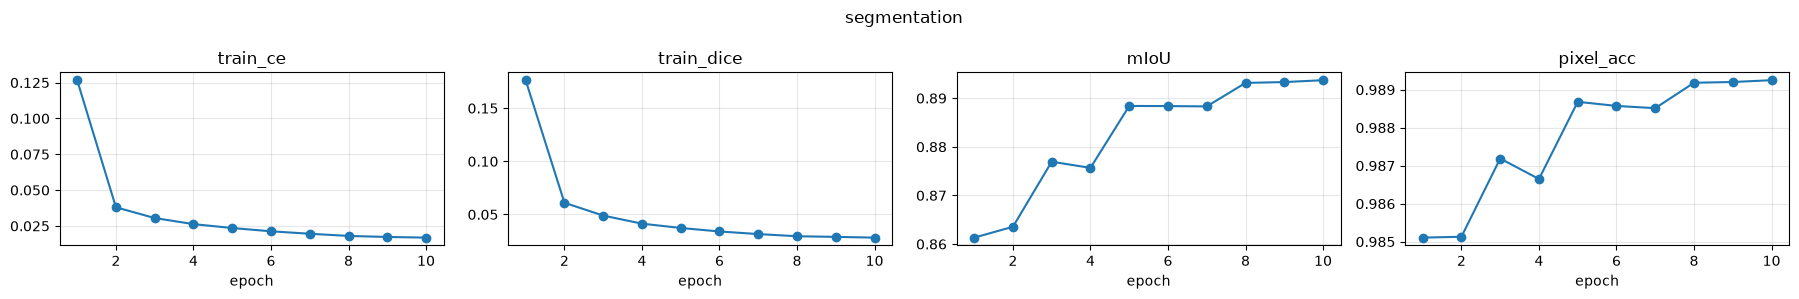

In [31]:
seg_hist = fit(seg_model, seg_task, train_loader, val_loader, SEG_EPOCHS, SEG_CKPT)
seg_hist.to_csv(RUN_DIR / "seg_history.csv", index=False)
plot_history(seg_hist, ["train_ce", "train_dice", "mIoU", "pixel_acc"], "segmentation")

In [32]:
load_best(seg_model, SEG_CKPT)
seg_results = {"val": seg_task.evaluate(seg_model, val_loader)}
if test_loader is not None:
    seg_results["test"] = seg_task.evaluate(seg_model, test_loader)
pd.DataFrame(seg_results).round(4)

loaded seg_dpt_best.pt (epoch 10, val {'mIoU': 0.8936963141478647, 'pixel_acc': 0.9892502960498734, 'IoU_Lunar Regolith': 0.9882658889858144, 'IoU_Impact Crater': 0.8465491234434629, 'IoU_Rock': 0.7401115918797685, 'IoU_Mountain': 0.9000109702331897, 'IoU_Sky': 0.9935439961970873})


,val,test
mIoU,0.8937,0.8382
pixel_acc,0.9893,0.9829
IoU_Lunar Regolith,0.9883,0.9807
IoU_Impact Crater,0.8465,0.5818
IoU_Rock,0.7401,0.7633
IoU_Mountain,0.9000,0.8723
IoU_Sky,0.9935,0.9931


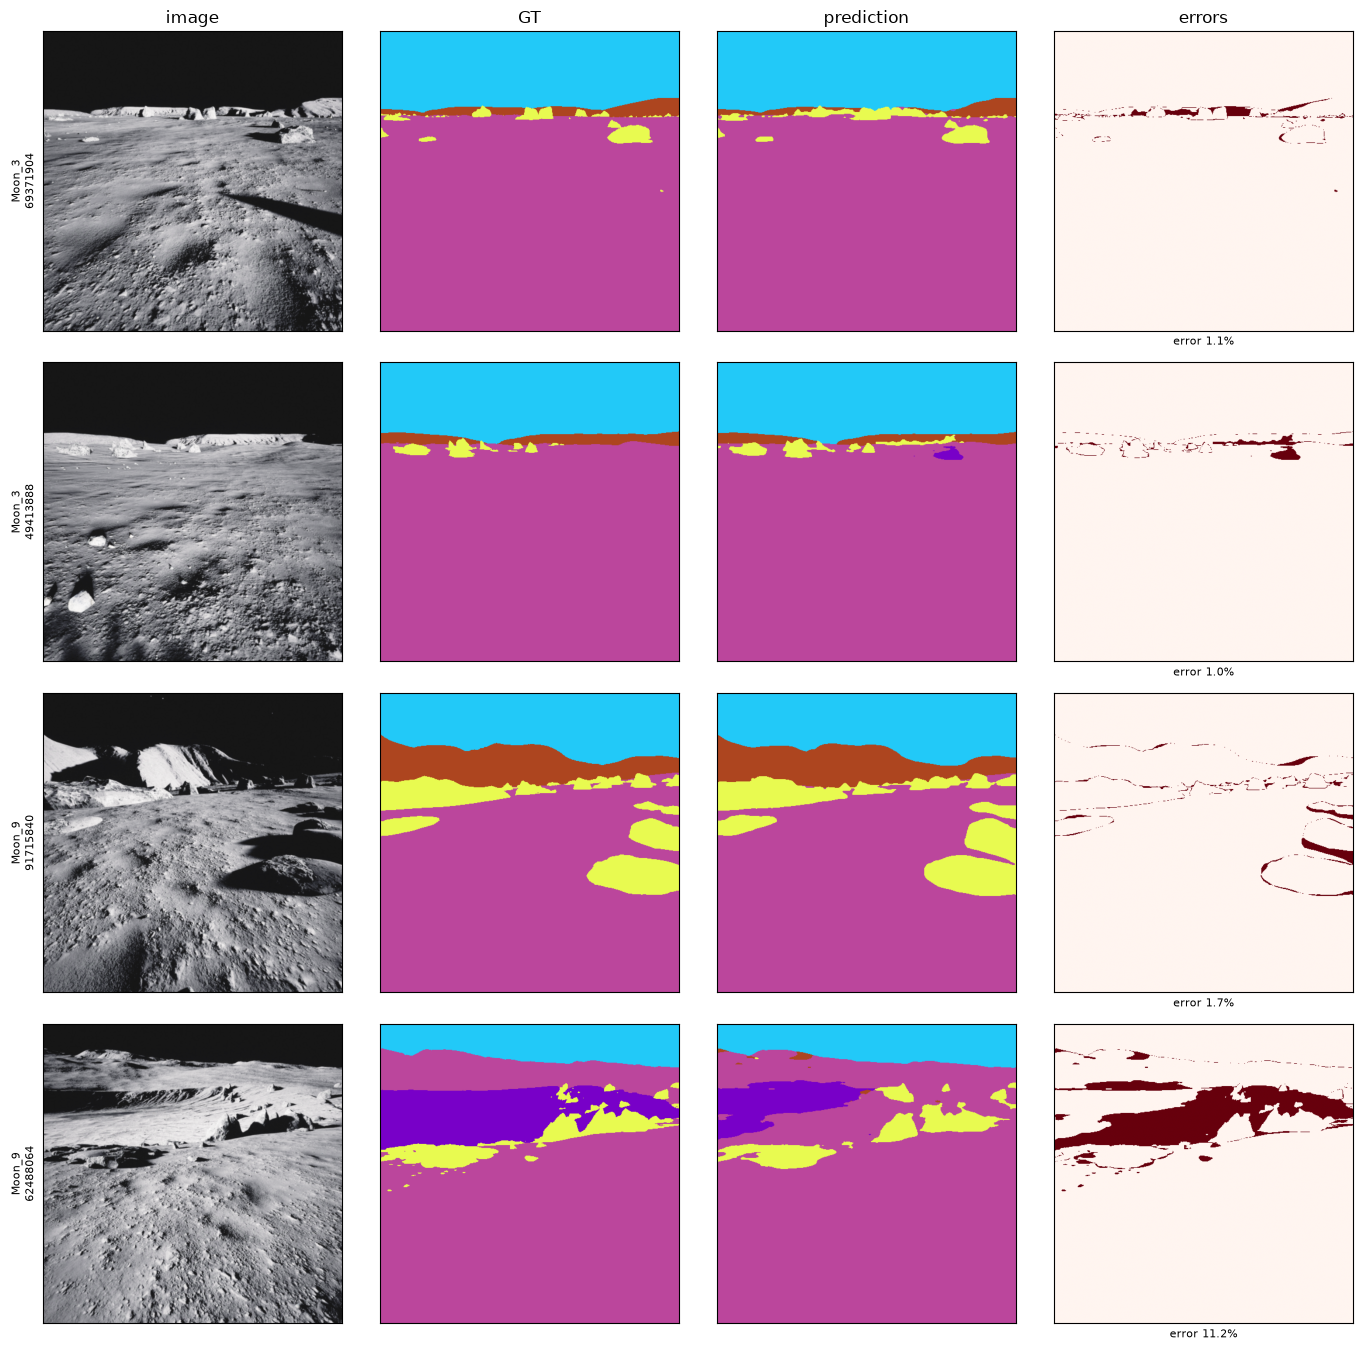

In [33]:
def show_seg(model, ds, n=4):
    ids = np.linspace(0, len(ds) - 1, n).astype(int)
    s = [ds[int(i)] for i in ids]
    x = torch.stack([t["image"] for t in s]).to(DEVICE)
    with torch.no_grad(), autocast():
        pred = model.eval()(x).argmax(1).cpu().numpy()
    fig, ax = plt.subplots(n, 4, figsize=(14, 3.4 * n), squeeze=False)
    for i in range(n):
        gt = s[i]["label"].numpy()
        err = (pred[i] != gt) & (gt != L.IGNORE_INDEX)
        ax[i, 0].imshow(L.denormalize(s[i]["image"]).permute(1, 2, 0).numpy())
        ax[i, 1].imshow(L.class_to_rgb(gt)); ax[i, 2].imshow(L.class_to_rgb(pred[i]))
        ax[i, 3].imshow(err, cmap="Reds"); ax[i, 3].set_xlabel(f"error {err.mean():.1%}", fontsize=8)
        ax[i, 0].set_ylabel(f"{s[i]['scene']}\n{s[i]['stem'][-8:]}", fontsize=8)
    for a, t in zip(ax[0], ["image", "GT", "prediction", "errors"]):
        a.set_title(t)
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_seg(seg_model, datasets.get("test", datasets["val"]))

In [34]:
# Free the segmentation model before training the depth model
del seg_model; gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 5. Depth estimation model

Same DPT architecture and a fresh backbone copy, with the depth-bin head. Sky pixels are invalid in
`depth_valid` and never enter the loss.

Loss: `L.silog_loss` (scale-invariant log, λ = 0.85) plus `GRAD_LOSS_WEIGHT` × a gradient-matching term on
log-depth, which sharpens rock and crater edges. Metrics are averaged per image over valid pixels: AbsRel, SqRel,
RMSE, RMSE_log, SILog and δ<1.25ⁿ. The checkpoint with the lowest val AbsRel is kept.

In [35]:
def gradient_loss(pred, gt, valid, eps=1e-6):
    v = valid.bool() & (gt > eps)
    d = torch.where(v, torch.log(pred.clamp_min(eps)) - torch.log(gt.clamp_min(eps)), torch.zeros_like(pred))
    mx, my = v[..., :, 1:] & v[..., :, :-1], v[..., 1:, :] & v[..., :-1, :]
    gx, gy = (d[..., :, 1:] - d[..., :, :-1]).abs(), (d[..., 1:, :] - d[..., :-1, :]).abs()
    return (gx[mx].sum() + gy[my].sum()) / (mx.sum() + my.sum()).clamp_min(1)


class DepthTask:
    main_metric, higher_is_better = "AbsRel", False

    def __init__(self, grad_weight=GRAD_LOSS_WEIGHT):
        self.grad_w = grad_weight

    def loss(self, pred, b):
        si = L.silog_loss(pred, b["depth"], b["depth_valid"])
        gr = gradient_loss(pred, b["depth"], b["depth_valid"])
        return si + self.grad_w * gr, {"silog": si.item(), "grad": gr.item()}

    @torch.no_grad()
    def evaluate(self, model, loader, max_batches=None):
        model.eval()
        keys = ["AbsRel", "SqRel", "RMSE", "RMSE_log", "SILog", "d1", "d2", "d3"]
        acc, n = dict.fromkeys(keys, 0.0), 0
        total = len(loader) if max_batches is None else min(len(loader), max_batches)
        for i, b in enumerate(tqdm(loader, total=total, desc="eval", leave=False)):
            if max_batches is not None and i >= max_batches:
                break
            b = to_device(b)
            with autocast():
                pred = model(b["image"]).float()
            for j in range(pred.shape[0]):
                v = b["depth_valid"][j, 0]
                if v.sum() < 10:
                    continue
                p, g = pred[j, 0][v].clamp_min(1e-3), b["depth"][j, 0][v]
                r, e = torch.maximum(p / g, g / p), torch.log(p) - torch.log(g)
                m = {"AbsRel": ((p - g).abs() / g).mean(), "SqRel": ((p - g) ** 2 / g).mean(),
                     "RMSE": ((p - g) ** 2).mean().sqrt(), "RMSE_log": (e ** 2).mean().sqrt(),
                     "SILog": 100 * ((e ** 2).mean() - e.mean() ** 2).clamp_min(0).sqrt(),
                     "d1": (r < 1.25).float().mean(), "d2": (r < 1.25 ** 2).float().mean(), "d3": (r < 1.25 ** 3).float().mean()}
                for k in keys:
                    acc[k] += float(m[k])
                n += 1
        return {k: v / max(n, 1) for k, v in acc.items()}

In [36]:
depth_model, PRETRAINED = build_model(DepthHead(n_bins=N_DEPTH_BINS, d_min=DEPTH_MIN, d_max=DEPTH_MAX))
depth_task = DepthTask()
DEPTH_CKPT = RUN_DIR / "depth_dpt_best.pt"

with torch.no_grad(), autocast():
    _p = depth_model.eval()(_b["image"][:2].to(DEVICE))
    print("depth:", tuple(_p.shape), f"range {_p.min().item():.2f}-{_p.max().item():.2f} m")

Loaded pretrained weights from /proj/uppmax2026-1-299/task1_groupc_dataset/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth
backbone 85.7M (trainable 0.0M) | neck 24.5M | head 0.34M
depth: (2, 1, 512, 512) range 41.95-42.07 m


epoch 1/10: 100%|████████████████████████| 1042/1042 [03:49<00:00,  4.54batch/s, silog=0.2742, grad=0.0089, lr=2.0e-04]


epoch 1/10 | train_silog 0.2742 train_grad 0.0089 | val AbsRel 0.0909  *best* | 251s


epoch 2/10: 100%|████████████████████████| 1042/1042 [02:52<00:00,  6.05batch/s, silog=0.1139, grad=0.0075, lr=1.9e-04]


epoch 2/10 | train_silog 0.1139 train_grad 0.0075 | val AbsRel 0.0779  *best* | 193s


epoch 3/10: 100%|████████████████████████| 1042/1042 [03:14<00:00,  5.37batch/s, silog=0.0910, grad=0.0069, lr=1.7e-04]


epoch 3/10 | train_silog 0.0910 train_grad 0.0069 | val AbsRel 0.0593  *best* | 215s


... (10 outputs left out)

epoch 9/10: 100%|████████████████████████| 1042/1042 [02:31<00:00,  6.88batch/s, silog=0.0582, grad=0.0062, lr=7.4e-06]


epoch 9/10 | train_silog 0.0582 train_grad 0.0062 | val AbsRel 0.0559 | 175s


epoch 10/10: 100%|███████████████████████| 1042/1042 [02:37<00:00,  6.61batch/s, silog=0.0572, grad=0.0062, lr=2.0e-06]


epoch 10/10 | train_silog 0.0572 train_grad 0.0062 | val AbsRel 0.0554 | 191s


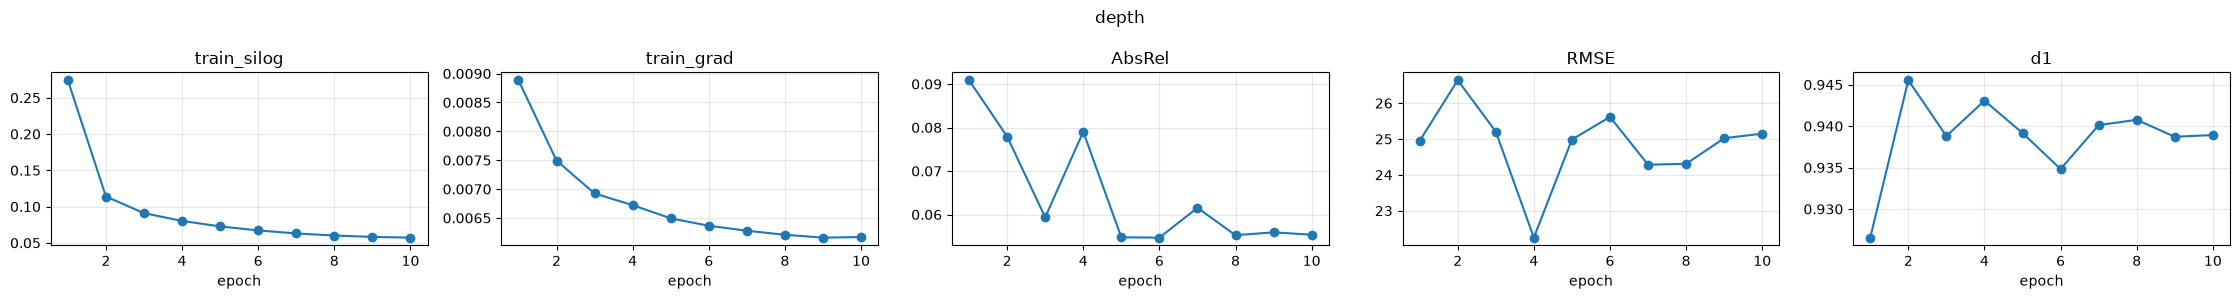

In [37]:
depth_hist = fit(depth_model, depth_task, train_loader, val_loader, DEPTH_EPOCHS, DEPTH_CKPT)
depth_hist.to_csv(RUN_DIR / "depth_history.csv", index=False)
plot_history(depth_hist, ["train_silog", "train_grad", "AbsRel", "RMSE", "d1"], "depth")

In [38]:
load_best(depth_model, DEPTH_CKPT)
depth_results = {"val": depth_task.evaluate(depth_model, val_loader)}
if test_loader is not None:
    depth_results["test"] = depth_task.evaluate(depth_model, test_loader)
pd.DataFrame(depth_results).round(4)

loaded depth_dpt_best.pt (epoch 6, val {'AbsRel': 0.054685532569686716, 'SqRel': 2.411318967070604, 'RMSE': 25.614288763502277, 'RMSE_log': 0.131267350351784, 'SILog': 12.58367531604894, 'd1': 0.9348163077515377, 'd2': 0.9751279332477194, 'd3': 0.9928969781898199})


,val,test
AbsRel,0.0547,0.1376
SqRel,2.4113,6.7846
RMSE,25.6143,43.8195
RMSE_log,0.1313,0.2384
SILog,12.5837,19.5458
d1,0.9348,0.7598
d2,0.9751,0.9536
d3,0.9929,0.9762


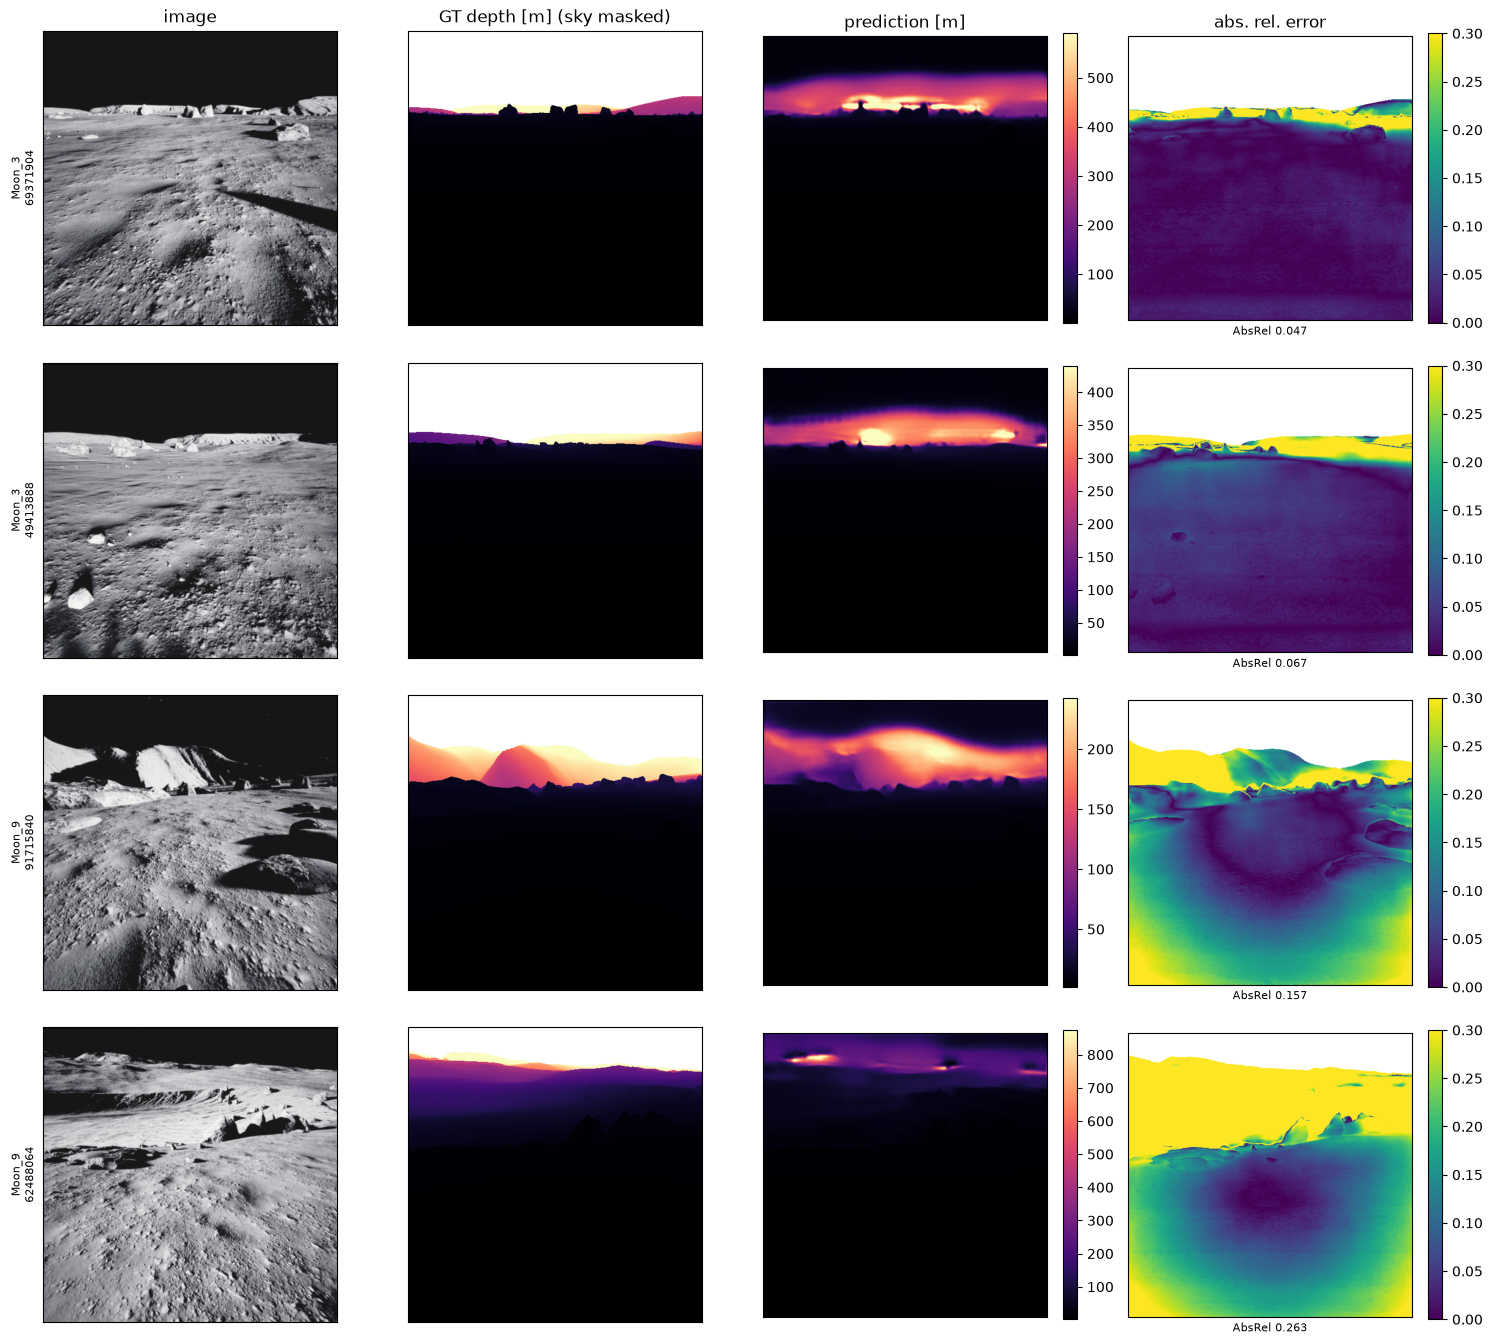

In [39]:
def show_depth(model, ds, n=4):
    ids = np.linspace(0, len(ds) - 1, n).astype(int)
    s = [ds[int(i)] for i in ids]
    x = torch.stack([t["image"] for t in s]).to(DEVICE)
    with torch.no_grad(), autocast():
        pred = model.eval()(x).float().cpu().numpy()
    fig, ax = plt.subplots(n, 4, figsize=(15, 3.4 * n), squeeze=False)
    for i in range(n):
        v = s[i]["depth_valid"][0].numpy()
        g = s[i]["depth"][0].numpy().copy(); g[~v] = np.nan
        p = pred[i, 0]; pm = p.copy(); pm[~v] = np.nan
        rel = np.abs(pm - g) / g
        vmin, vmax = np.nanpercentile(g, [1, 99])
        ax[i, 0].imshow(L.denormalize(s[i]["image"]).permute(1, 2, 0).numpy())
        ax[i, 1].imshow(g, cmap="magma", vmin=vmin, vmax=vmax)
        im = ax[i, 2].imshow(p, cmap="magma", vmin=vmin, vmax=vmax); plt.colorbar(im, ax=ax[i, 2], fraction=0.046)
        im = ax[i, 3].imshow(rel, cmap="viridis", vmin=0, vmax=0.3); plt.colorbar(im, ax=ax[i, 3], fraction=0.046)
        ax[i, 3].set_xlabel(f"AbsRel {np.nanmean(rel):.3f}", fontsize=8)
        ax[i, 0].set_ylabel(f"{s[i]['scene']}\n{s[i]['stem'][-8:]}", fontsize=8)
    for a, t in zip(ax[0], ["image", "GT depth [m] (sky masked)", "prediction [m]", "abs. rel. error"]):
        a.set_title(t)
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_depth(depth_model, datasets.get("test", datasets["val"]))

## 6. Summary

In [40]:
summary = {"backbone": DINO_ID if PRETRAINED else "RANDOM (no pretrained weights!)",
           "image_size": IMAGE_SIZE, "unfreeze_last_n": UNFREEZE_LAST_N,
           "segmentation": seg_results, "depth": depth_results}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "backbone": "facebook/dinov3-vitb16-pretrain-lvd1689m",
  "image_size": 512,
  "unfreeze_last_n": 0,
  "segmentation": {
    "val": {
      "mIoU": 0.8936963141478647,
      "pixel_acc": 0.9892502960498734,
      "IoU_Lunar Regolith": 0.9882658889858144,
      "IoU_Impact Crater": 0.8465491234434629,
      "IoU_Rock": 0.7401115918797685,
      "IoU_Mountain": 0.9000109702331897,
      "IoU_Sky": 0.9935439961970873
    },
    "test": {
      "mIoU": 0.8382451346453859,
      "pixel_acc": 0.9828693561249193,
      "IoU_Lunar Regolith": 0.9806743860433041,
      "IoU_Impact Crater": 0.581844405989679,
      "IoU_Rock": 0.7632673212516231,
      "IoU_Mountain": 0.8723240173115595,
      "IoU_Sky": 0.9931155426307632
    }
  },
  "depth": {
    "val": {
      "AbsRel": 0.054685532569686716,
      "SqRel": 2.411318967070604,
      "RMSE": 25.614288763502277,
      "RMSE_log": 0.131267350351784,
      "SILog": 12.58367531604894,
      "d1": 0.9348163077515377,
      "d2": 0.97512793324771